In [1]:
import pandas as pd
from pathlib import Path
from PIL import Image
from torchvision import transforms
import matplotlib.pyplot as plt 
import torch 

EPILL = Path("../data/raw/epillid/ePillID_data")
OUT = Path("../data/processed")
# train = pd.read_csv(OUT/"train.csv")
# print(train.shape)
# ref = train[train.is_ref].reset_index(drop=True)



device = "cuda" if torch.cuda.is_available() else "cpu"
print("using:", device)
train = pd.read_csv(OUT / "train.csv")
val = pd.read_csv(OUT / "val.csv")
print(len(train), len(val))      # expect 188 40
ref = train[train.is_ref].reset_index(drop=True)
pills = sorted(ref.pilltype_id.unique())
print(len(ref), len(pills))      # expect 80 40
preprocess = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

using: cuda
188 40
80 40


In [2]:
from torch.utils.data import Dataset





class PillDataset(Dataset):
    def __init__(self, csv_path, pills, transform):
        self.df = pd.read_csv(csv_path).reset_index(drop=True)
        self.transform = transform
        self.to_idx = {p: i for i, p in enumerate(pills)}

    def __len__(self):
        return len(self.df)

    def __getitem__(self, i):
        r = self.df.iloc[i]
        img = Image.open(EPILL / "classification_data" / r.image_path).convert("RGB")
        return self.transform(img), self.to_idx[r.pilltype_id]




In [3]:
pills = sorted(ref.pilltype_id.unique())
ds = PillDataset(OUT / "train.csv", pills, preprocess)
print(len(ds))
x, y = ds[0]
print(x.shape, y)

188
torch.Size([3, 224, 224]) 3


In [4]:
train_tf = transforms.Compose([
    transforms.RandomResizedCrop(224, scale=(0.7, 1.0)),
    transforms.RandomRotation(30),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

train_ds = PillDataset(OUT / "train.csv", pills, train_tf)
val_ds = PillDataset(OUT / "val.csv", pills, preprocess)

In [5]:
from torch.utils.data import DataLoader
from torchvision.models import mobilenet_v3_small, MobileNet_V3_Small_Weights

train_dl = DataLoader(train_ds, batch_size=16, shuffle=True, num_workers=0)
val_dl = DataLoader(val_ds, batch_size=16, shuffle=False, num_workers=0)





model = mobilenet_v3_small(weights=MobileNet_V3_Small_Weights.DEFAULT)
print(model.classifier)

model.classifier[3] = torch.nn.Linear(1024, len(pills))
model = model.to(device)

x, y = next(iter(train_dl))
print(x.shape, y.shape)
out = model(x.to(device))
print(out.shape)

Sequential(
  (0): Linear(in_features=576, out_features=1024, bias=True)
  (1): Hardswish()
  (2): Dropout(p=0.2, inplace=True)
  (3): Linear(in_features=1024, out_features=1000, bias=True)
)
torch.Size([16, 3, 224, 224]) torch.Size([16])
torch.Size([16, 40])


In [6]:
import time
import torch.nn as nn

loss_fn = nn.CrossEntropyLoss()
opt = torch.optim.AdamW(model.parameters(), lr=3e-4)


def evaluate(model, dl):
    model.eval()
    top1 = top5 = n = 0
    with torch.no_grad():
        for x, y in dl:
            out = model(x.to(device)).cpu()
            top5_idx = out.topk(5, dim=1).indices
            top1 += (top5_idx[:, 0] == y).sum().item()
            top5 += (top5_idx == y[:, None]).any(dim=1).sum().item()
            n += len(y)
    return top1 / n, top5 / n







import json, shutil
SAVE = Path("../models/best_classifier.pt")
SCORE = Path("../models/best_score.json")
Path("../models").mkdir(exist_ok=True)
if SAVE.exists():
    shutil.copy(SAVE, "../models/backup_before_run.pt")
saved_best = json.load(open(SCORE))["top1"] if SCORE.exists() else 0






best = 0
epochs = 20
for epoch in range(epochs):
    t0 = time.time()
    model.train()
    total = 0
    for x, y in train_dl:
        x, y = x.to(device), y.to(device)
        opt.zero_grad()
        loss = loss_fn(model(x), y)
        loss.backward()
        opt.step()
        total += loss.item() * len(y)
    v1, v5 = evaluate(model, val_dl)
    print(f"epoch {epoch+1:2d}  train loss {total/len(train_ds):.3f}  val top-1 {v1:.3f}  top-5 {v5:.3f}  ({time.time()-t0:.0f}s)")
    if v1 > best:
        best = v1
    if v1 > saved_best:
        saved_best = v1
        torch.save(model.state_dict(), SAVE)
        json.dump({"top1": v1}, open(SCORE, "w"))

epoch  1  train loss 3.646  val top-1 0.050  top-5 0.225  (2s)
epoch  2  train loss 3.142  val top-1 0.150  top-5 0.450  (1s)
epoch  3  train loss 2.578  val top-1 0.275  top-5 0.575  (1s)
epoch  4  train loss 1.971  val top-1 0.350  top-5 0.725  (3s)
epoch  5  train loss 1.499  val top-1 0.425  top-5 0.725  (3s)
epoch  6  train loss 1.263  val top-1 0.500  top-5 0.800  (2s)
epoch  7  train loss 0.987  val top-1 0.575  top-5 0.850  (2s)
epoch  8  train loss 0.692  val top-1 0.600  top-5 0.875  (2s)
epoch  9  train loss 0.546  val top-1 0.600  top-5 0.925  (2s)
epoch 10  train loss 0.490  val top-1 0.575  top-5 0.950  (3s)
epoch 11  train loss 0.319  val top-1 0.650  top-5 0.975  (3s)
epoch 12  train loss 0.329  val top-1 0.650  top-5 0.975  (3s)
epoch 13  train loss 0.263  val top-1 0.800  top-5 1.000  (3s)
epoch 14  train loss 0.218  val top-1 0.775  top-5 0.975  (3s)
epoch 15  train loss 0.202  val top-1 0.800  top-5 1.000  (3s)
epoch 16  train loss 0.159  val top-1 0.725  top-5 0.97

In [7]:
print(model.classifier[3].weight.shape)
print(model.classifier[3].bias.shape)

torch.Size([40, 1024])
torch.Size([40])


In [8]:
model.load_state_dict(torch.load("../models/best_classifier.pt", map_location=device))
print(evaluate(model, val_dl))  

(0.825, 0.925)


7 wrong


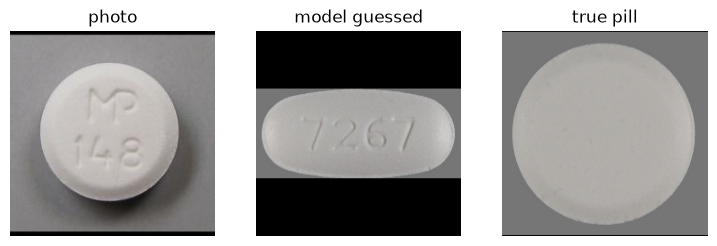

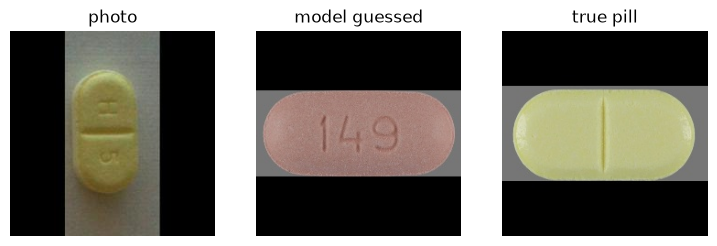

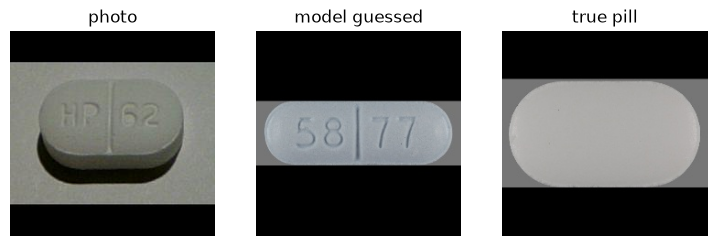

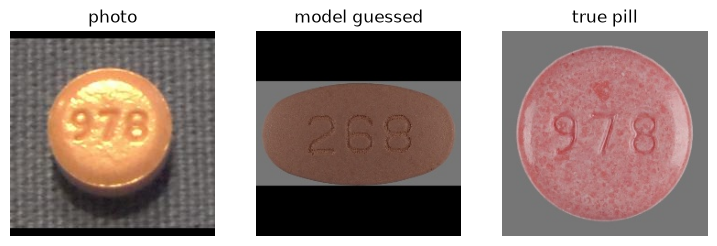

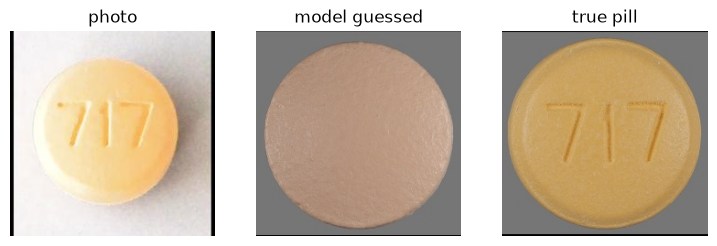

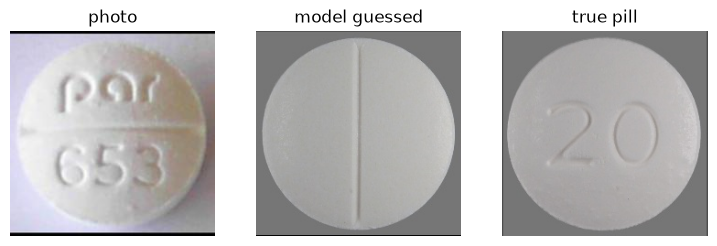

In [9]:
import matplotlib.pyplot as plt


model.eval()
preds, trues = [], []
with torch.no_grad():
    for x, y in val_dl:
        out = model(x.to(device)).cpu()
        preds += out.argmax(dim=1).tolist()
        trues += y.tolist()


wrong = [i for i in range(len(trues)) if preds[i] != trues[i]]
print(len(wrong), "wrong")




for i in wrong[:6]:
    q = val.image_path[i]
    p_ref = ref[ref.pilltype_id == pills[preds[i]]].image_path.iloc[0]
    t_ref = ref[ref.pilltype_id == pills[trues[i]]].image_path.iloc[0]
    fig, axes = plt.subplots(1, 3, figsize=(9, 3))
    for ax, path, title in zip(axes, [q, p_ref, t_ref], ["photo", "model guessed", "true pill"]):
        ax.imshow(Image.open(EPILL / "classification_data" / path))
        ax.set_title(title)
        ax.axis("off")
    plt.show()

In [10]:
#for noise 
import random
import numpy as np

def run_training(seed, epochs=20, batch_size=16, lr=3e-4):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)




    m = mobilenet_v3_small(weights=MobileNet_V3_Small_Weights.DEFAULT)
    m.classifier[3] = torch.nn.Linear(1024, len(pills))
    m = m.to(device)

    tdl = DataLoader(train_ds, batch_size=batch_size, shuffle=True, num_workers=0)
    opt = torch.optim.AdamW(m.parameters(), lr=lr)


    best = (0, 0)
    for epoch in range(epochs):
        m.train()
        for x, y in tdl:
            x, y = x.to(device), y.to(device)
            opt.zero_grad()
            loss = loss_fn(m(x), y)
            loss.backward()
            opt.step()
        v = evaluate(m, val_dl)
        if v[0] > best[0]:
            best = v
    return best, v






results = []
for seed in [0, 1, 2, 3, 4]:
    best, last = run_training(seed)
    results.append((best, last))
    print(seed, "best epoch:", best, " last epoch:", last)




last_top1 = np.array([r[1][0] for r in results])
last_top5 = np.array([r[1][1] for r in results])
print(f"last epoch top-1: {last_top1.mean():.3f} +/- {last_top1.std():.3f}")
print(f"last epoch top-5: {last_top5.mean():.3f} +/- {last_top5.std():.3f}")    

0 best epoch: (0.725, 0.9)  last epoch: (0.7, 0.925)
1 best epoch: (0.8, 0.925)  last epoch: (0.775, 0.95)
2 best epoch: (0.775, 0.95)  last epoch: (0.7, 1.0)
3 best epoch: (0.75, 0.95)  last epoch: (0.75, 0.975)
4 best epoch: (0.825, 0.975)  last epoch: (0.75, 0.95)
last epoch top-1: 0.735 +/- 0.030
last epoch top-5: 0.960 +/- 0.025


In [11]:
model.load_state_dict(torch.load("../models/best_classifier.pt", map_location=device))
print(evaluate(model, val_dl))

(0.825, 0.925)


In [12]:
model.eval()
preds, trues = [], []

with torch.no_grad():
    for x, y in val_dl:
        out = model(x.to(device)).cpu()
        preds += out.argmax(dim=1).tolist()
        trues += y.tolist()

        
wrong = [i for i in range(len(trues)) if preds[i] != trues[i]]
print(len(wrong), "wrong out of", len(trues))

7 wrong out of 40


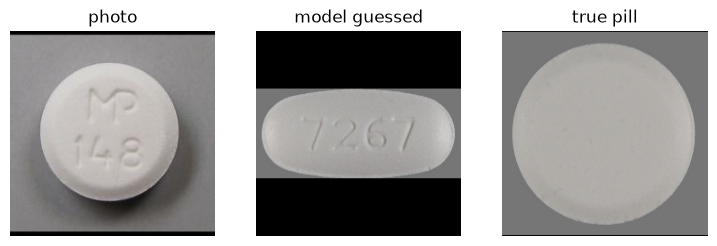

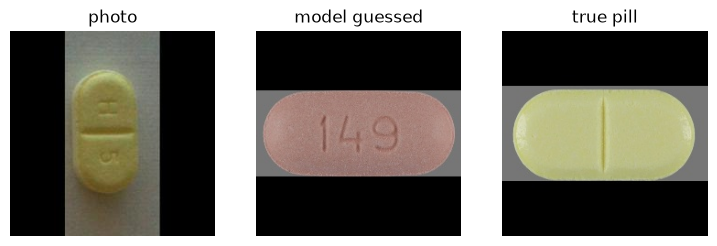

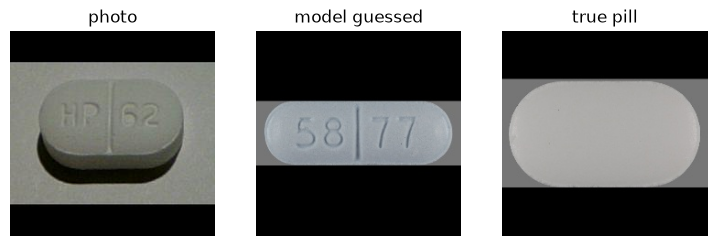

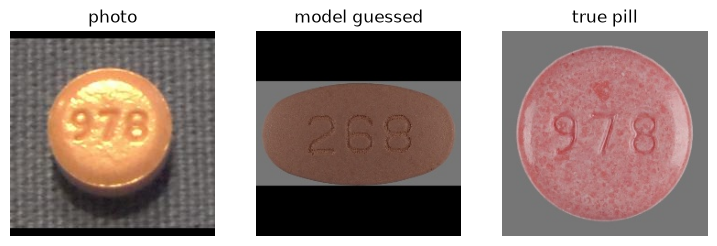

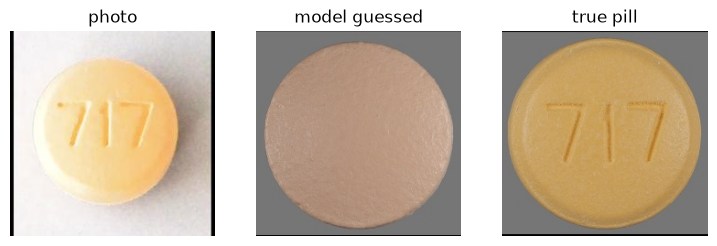

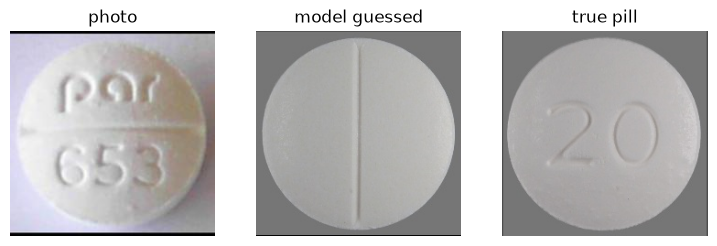

In [13]:
import matplotlib.pyplot as plt
for i in wrong[:6]:
    q = val.image_path[i]
    p_ref = ref[ref.pilltype_id == pills[preds[i]]].image_path.iloc[0]
    t_ref = ref[ref.pilltype_id == pills[trues[i]]].image_path.iloc[0]
    fig, axes = plt.subplots(1, 3, figsize=(9, 3))
    for ax, path, title in zip(axes, [q, p_ref, t_ref], ["photo", "model guessed", "true pill"]):
        ax.imshow(Image.open(EPILL / "classification_data" / path))
        ax.set_title(title)
        ax.axis("off")
    plt.show()